# CNN FC128 và MLP một lớp ẩn 260 nơ-ron

Hai mạng PyTorch có số tham số gần bằng nhau: MLP 206.710, CNN 206.922. Cùng split, thứ tự batch, SGD, learning rate, batch size và số epoch. Chọn checkpoint bằng validation loss; test không dùng lựa chọn. Một seed chỉ cho kết quả của lần chạy này, không chứng minh mô hình nào luôn tốt hơn.

## 1. Dữ liệu và cấu hình

Loader trả về 4 giá trị `(X, y, X_test, y_test)`; ảnh đã chia 255, chỉ reshape. Chia stratify 50.000 train / 10.000 validation với seed 42.

In [7]:
from pathlib import Path
import sys, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, ConfusionMatrixDisplay
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.data import load_prepared_mnist
OUTPUT = ROOT / 'results' / 'cnn_mlp'
OUTPUT.mkdir(parents=True, exist_ok=True)
SEED, EPOCHS, BATCH_SIZE = 42, 50, 256
LR, MOMENTUM = 0.01, 0.9
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

X, y, X_test, y_test = load_prepared_mnist()
X, y = np.asarray(X, dtype=np.float32), np.asarray(y, dtype=int)
X_test, y_test = np.asarray(X_test, dtype=np.float32), np.asarray(y_test, dtype=int)
tr, va = train_test_split(np.arange(len(y)), test_size=10000, stratify=y, random_state=SEED)
data = {'Train': (X[tr], y[tr]), 'Validation': (X[va], y[va]), 'Test': (X_test, y_test)}
datasets = {name: TensorDataset(torch.from_numpy(a.reshape(-1,1,28,28)), torch.as_tensor(b, dtype=torch.long))
            for name, (a,b) in data.items()}
loaders = {name: DataLoader(ds, batch_size=BATCH_SIZE, shuffle=False) for name, ds in datasets.items()}
print('Device:', DEVICE)
for name, ds in datasets.items(): print(name, len(ds))
del X

Device: cpu
Train 50000
Validation 10000
Test 10000


## 2. Khai báo hai mô hình bằng thư viện

MLP làm phẳng ảnh thành 784 pixel, qua lớp ẩn 260 nơ-ron. CNN giữ cấu trúc ảnh qua Conv–ReLU–Pool hai lần, rồi Flatten–FC128–FC10. Hai đầu ra đều là 10 logits; không đặt softmax trước `CrossEntropyLoss`.

Số tham số gần nhau không có nghĩa số phép tính hay thời gian bằng nhau. Cấu hình huấn luyện chung cũng chưa bảo đảm tối ưu riêng cho từng mạng.

In [8]:
def make_mlp():
    return nn.Sequential(
        nn.Flatten(), nn.Linear(784,260), nn.ReLU(), nn.Linear(260,10))

def make_cnn():
    return nn.Sequential(
        nn.Conv2d(1,16,3,padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(16,32,3,padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Flatten(), nn.Linear(32*7*7,128), nn.ReLU(), nn.Linear(128,10))

makers = {'MLP260': make_mlp, 'CNN_FC128': make_cnn}
parameters = {name: sum(p.numel() for p in make().parameters()) for name, make in makers.items()}
display(pd.DataFrame({'model': list(parameters), 'parameters': list(parameters.values())}))

,model,parameters
0,MLP260,206710
1,CNN_FC128,206922


## 3. Hàm huấn luyện chung

Mỗi mạng chạy đủ 15 epoch, cùng generator shuffle để nhận cùng thứ tự mini-batch. Seed được đặt lại trước khi khởi tạo từng mạng, nhưng không có nghĩa hai kiến trúc có trọng số khởi tạo giống nhau. Sau mỗi epoch, đánh giá train/validation với trọng số cuối epoch; giữ validation loss thấp nhất, hòa giữ epoch sớm hơn. Không early stopping.

In [9]:
@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    loss_sum, count, predictions = 0.0, 0, []
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        logits = model(xb)
        loss_sum += nn.functional.cross_entropy(logits, yb, reduction='sum').item()
        count += len(yb)
        predictions.append(logits.argmax(1).cpu().numpy())
    return loss_sum/count, np.concatenate(predictions)

def train_model(make):
    torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    model = make().to(DEVICE)
    train_loader = DataLoader(datasets['Train'], batch_size=BATCH_SIZE, shuffle=True,
                              generator=torch.Generator().manual_seed(SEED))
    optimizer = torch.optim.SGD(model.parameters(), lr=LR, momentum=MOMENTUM)
    history, best_loss, best_state, best_epoch = [], np.inf, None, None
    if DEVICE.type == 'cuda': torch.cuda.synchronize()
    start = time.perf_counter()
    with torch.enable_grad():
        for epoch in range(1,EPOCHS+1):
            model.train()
            for xb, yb in train_loader:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                optimizer.zero_grad(set_to_none=True)
                loss = nn.functional.cross_entropy(model(xb), yb)
                loss.backward()
                optimizer.step()
            train_loss, train_pred = evaluate(model, loaders['Train'])
            val_loss, val_pred = evaluate(model, loaders['Validation'])
            history.append(dict(epoch=epoch, train_loss=train_loss, val_loss=val_loss,
                train_accuracy=accuracy_score(data['Train'][1],train_pred),
                val_accuracy=accuracy_score(data['Validation'][1],val_pred)))
            if val_loss < best_loss:
                best_loss, best_epoch = val_loss, epoch
                best_state = {k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
            print(f'Epoch {epoch:02d} | train loss={train_loss:.4f} | val loss={val_loss:.4f} | val acc={history[-1]["val_accuracy"]:.4f}', flush=True)
    if DEVICE.type == 'cuda': torch.cuda.synchronize()
    seconds = time.perf_counter()-start
    model.load_state_dict(best_state)
    model.eval()
    return model, pd.DataFrame(history), best_epoch, seconds

## 4. Huấn luyện và vẽ đường học

Fit riêng hai mạng bằng cùng hàm. Đường học mô tả quá trình huấn luyện, kết quả cuối dùng checkpoint đã chọn. Thời gian gồm cập nhật trọng số và đánh giá mỗi epoch; một lượt đo chưa phải benchmark độc lập.

Huấn luyện: MLP260
Epoch 01 | train loss=0.4208 | val loss=0.4266 | val acc=0.8827
Epoch 02 | train loss=0.3338 | val loss=0.3430 | val acc=0.9043
Epoch 03 | train loss=0.2965 | val loss=0.3088 | val acc=0.9143
Epoch 04 | train loss=0.2703 | val loss=0.2849 | val acc=0.9206
Epoch 05 | train loss=0.2492 | val loss=0.2624 | val acc=0.9295
Epoch 06 | train loss=0.2297 | val loss=0.2480 | val acc=0.9314
Epoch 07 | train loss=0.2142 | val loss=0.2330 | val acc=0.9358
Epoch 08 | train loss=0.1980 | val loss=0.2188 | val acc=0.9399
Epoch 09 | train loss=0.1842 | val loss=0.2057 | val acc=0.9441
Epoch 10 | train loss=0.1730 | val loss=0.1942 | val acc=0.9478
Epoch 11 | train loss=0.1634 | val loss=0.1880 | val acc=0.9486
Epoch 12 | train loss=0.1539 | val loss=0.1776 | val acc=0.9520
Epoch 13 | train loss=0.1444 | val loss=0.1690 | val acc=0.9539
Epoch 14 | train loss=0.1375 | val loss=0.1646 | val acc=0.9568
Epoch 15 | train loss=0.1307 | val loss=0.1581 | val acc=0.9575
Epoch 16 | train loss

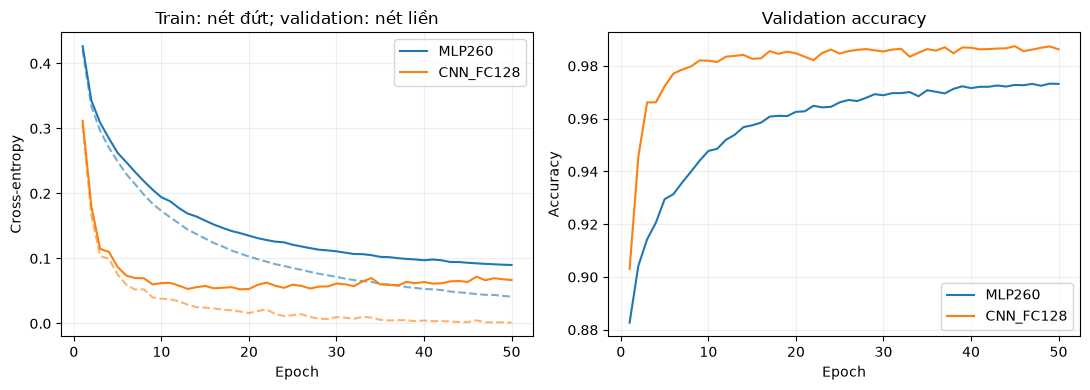

In [10]:
models, histories, best_epochs, fit_times = {}, {}, {}, {}
for name, make in makers.items():
    print('Huấn luyện:', name)
    models[name], histories[name], best_epochs[name], fit_times[name] = train_model(make)
    print('Checkpoint được chọn:', best_epochs[name])

fig, axes = plt.subplots(1,2,figsize=(11,4))
for name, h in histories.items():
    line, = axes[0].plot(h.epoch,h.val_loss,label=name)
    axes[0].plot(h.epoch,h.train_loss,linestyle='--',color=line.get_color(),alpha=.6)
    axes[1].plot(h.epoch,h.val_accuracy,label=name)
axes[0].set(xlabel='Epoch',ylabel='Cross-entropy',title='Train: nét đứt; validation: nét liền')
axes[1].set(xlabel='Epoch',ylabel='Accuracy',title='Validation accuracy')
for ax in axes: ax.legend(); ax.grid(alpha=.2)
fig.tight_layout();fig.savefig(OUTPUT/'learning_curves.png',dpi=300);plt.show()

## 5. Đánh giá hai checkpoint

Báo cáo accuracy, precision/recall/F1 macro và số lỗi trên cả ba tập. Train là in-sample, validation đã dùng chọn checkpoint. Confusion matrix test giúp thấy các hướng nhầm; không thay mô hình sau khi xem test.

,model,split,loss,accuracy,precision_macro,recall_macro,f1_macro,errors,parameters,best_epoch,fit_seconds
0,MLP260,Train,0.04118,0.99058,0.99059,0.99059,0.99059,471,206710,50,55.81281
1,MLP260,Validation,0.08996,0.97320,0.97308,0.97312,0.97307,268,206710,50,55.81281
2,MLP260,Test,0.07850,0.97570,0.97560,0.97551,0.97554,243,206710,50,55.81281
3,CNN_FC128,Train,0.01833,0.99422,0.99422,0.99424,0.99421,289,206922,19,332.49426
4,CNN_FC128,Validation,0.05253,0.98540,0.98537,0.98535,0.98534,146,206922,19,332.49426
5,CNN_FC128,Test,0.03664,0.98700,0.98695,0.98702,0.98696,130,206922,19,332.49426


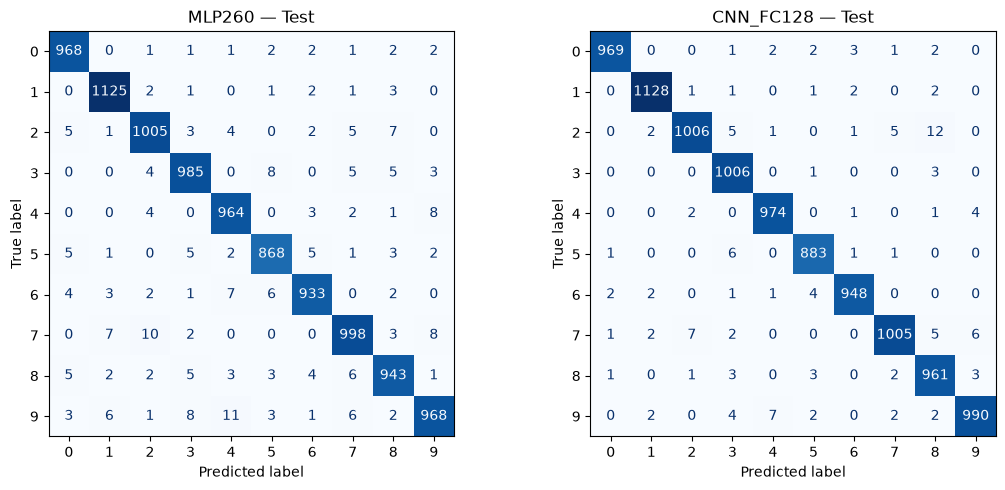

In [11]:
rows, predictions = [], {}
for name, model in models.items():
    for split, loader in loaders.items():
        loss, pred = evaluate(model,loader)
        target = data[split][1]
        precision, recall, f1, _ = precision_recall_fscore_support(target,pred,
            labels=np.arange(10),average='macro',zero_division=0)
        predictions[name,split] = pred
        rows.append(dict(model=name,split=split,loss=loss,accuracy=accuracy_score(target,pred),
            precision_macro=precision,recall_macro=recall,f1_macro=f1,
            errors=int((pred!=target).sum()),parameters=parameters[name],
            best_epoch=best_epochs[name],fit_seconds=fit_times[name]))
results = pd.DataFrame(rows)
display(results.round(5))
fig,axes = plt.subplots(1,2,figsize=(11,5))
for ax,name in zip(axes,makers):
    ConfusionMatrixDisplay.from_predictions(y_test,predictions[name,'Test'],labels=np.arange(10),
        ax=ax,cmap='Blues',colorbar=False,values_format='d')
    ax.set_title(name+' — Test')
fig.tight_layout();fig.savefig(OUTPUT/'confusion_test.png',dpi=300);plt.show()

## 6. Lưu kết quả và trọng số

Lưu metrics, lịch sử, split và mỗi mạng một checkpoint. Để suy luận: tạo lại đúng mạng bằng hàm ở mục 2, nạp `state_dict`, gọi `eval()` và đưa ảnh cùng tiền xử lý vào. Không tự chia 255 lần nữa nếu ảnh đã ở [0,1].

In [12]:
results.to_csv(OUTPUT/'metrics.csv',index=False)
results[results.split=='Test'].to_csv(OUTPUT/'comparison.csv',index=False)
np.savez_compressed(OUTPUT/'split_indices.npz',train_idx=tr,val_idx=va,seed=SEED)
config = dict(seed=SEED,epochs=EPOCHS,batch_size=BATCH_SIZE,learning_rate=LR,momentum=MOMENTUM,
    optimizer='SGD',checkpoint_rule='minimum validation cross-entropy; earlier epoch on ties',
    preprocessing='loader pixel /255; reshape N,1,28,28 only',
    architectures={'MLP260':'784-260-ReLU-10','CNN_FC128':'Conv16-ReLU-Pool-Conv32-ReLU-Pool-FC128-ReLU-FC10'},
    parameters=parameters,device=str(DEVICE),torch_version=str(torch.__version__))
(OUTPUT/'config.json').write_text(json.dumps(config,ensure_ascii=False,indent=2),encoding='utf-8')
for name, model in models.items():
    histories[name].to_csv(OUTPUT/f'history_{name}.csv',index=False)
    torch.save(dict(model_name=name,state_dict={k:v.detach().cpu() for k,v in model.state_dict().items()},
        best_epoch=best_epochs[name],classes=list(range(10)),config=config),OUTPUT/f'{name}.pt')
pd.DataFrame({'y_true':y_test,**{name:predictions[name,'Test'] for name in makers}}).to_csv(OUTPUT/'test_predictions.csv',index=False)
print('Đã lưu:',OUTPUT)

Đã lưu: d:\Nhận dạng mẫu\mnist\results\cnn_mlp
